# PathSnap — 01 Exploratory Data Analysis
Partitions used: **train (80 trips)** and **student_test (10 trips)**. Evaluator data is not used here.

In [1]:
import sys, os; sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data.loader import list_trips, load_trip
from src.data.geo import clean_track
from src.viz.maps import trip_map
sns.set_theme(style='whitegrid'); FIG='../reports/figures'
inv = pd.read_csv('../experiments/dataset_inventory.csv')
inv.groupby('partition')[['gps_points','duration_s','max_gap_s','nodes','arcs','route_len']].agg(['count','mean','median','min','max']).round(1)

gps_points                             duration_s          \
                  count    mean  median  min    max      count    mean   
partition                                                                
student_test         10  1916.0  1420.0  262   3958         10  2025.0   
train                80  2605.2  1529.0  361  19313         80  5680.4   

                                       ...  arcs                          \
              median    min       max  ... count     mean   median   min   
partition                              ...                                 
student_test  1809.5  265.0    4000.0  ...    10  18504.1  13145.0  3577   
train         1710.0  451.0  154030.0  ...    80  48461.3  19526.5   649   

                     route_len                          
                 max     count   mean median min   max  
partition                                               
student_test   56027        10  347.7  250.0  95  1323  
train         307392        80  391.7  280.0  59  2266  

[2 rows x 30 columns]

## 1. Missing values, timestamp order, file validity

In [2]:
print('Trips per partition:', inv.partition.value_counts().to_dict())
print('Rows with NaN:', inv.nan_rows.sum())
print('Non-increasing timestamps:', inv.non_monotonic_t.sum())
print('Route arc ids out of range:', (~inv.route_arcs_valid).sum())
print('Mean % of 1-second steps:', inv.pct_dt_1s.mean().round(1))

Trips per partition: {'train': 80, 'student_test': 10}
Rows with NaN: 0
Non-increasing timestamps: 0
Route arc ids out of range: 0
Mean % of 1-second steps: 94.3


## 2. Trajectory length and sampling gaps

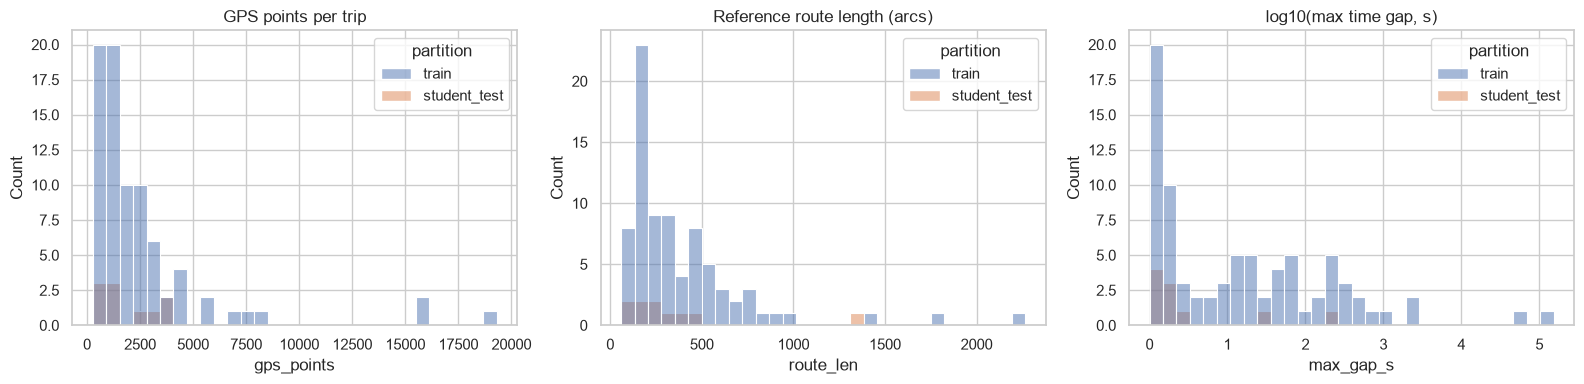

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=inv, x='gps_points', hue='partition', bins=30, ax=ax[0]); ax[0].set_title('GPS points per trip')
sns.histplot(data=inv, x='route_len', hue='partition', bins=30, ax=ax[1]); ax[1].set_title('Reference route length (arcs)')
sns.histplot(data=inv, x=np.log10(inv.max_gap_s), hue='partition', bins=30, ax=ax[2]); ax[2].set_title('log10(max time gap, s)')
plt.tight_layout(); plt.savefig(f'{FIG}/eda_lengths_gaps.png', dpi=120); plt.show()

Total steps: 208337 | dt==1s: 96.5% | dt>60s: 69


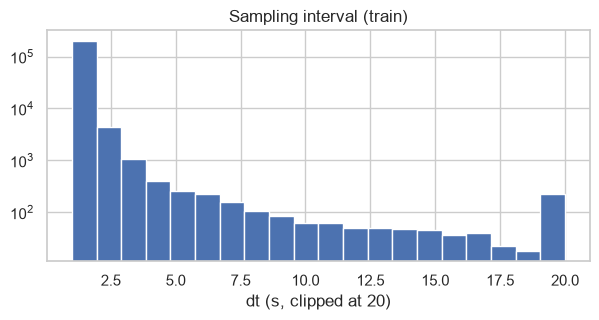

Trips with any gap > 60 s:
   partition  trip  gps_points  max_gap_s
       train    90         536   153064.0
       train    78        2909    52810.0
       train    69        2067     2658.0
       train    21       15783     2161.0
       train    11        2828      909.0
       train    42        7739      670.0
       train    81        3224      536.0
       train    24         801      458.0
       train    44         546      341.0
       train    84       16031      312.0
       train     6        1450      301.0
       train    88         876      232.0
       train    43        2322      230.0
student_test    65         768      210.0
       train    28        3565      196.0
       train    89        1228      193.0
       train    55        2472      184.0
       train     2        7243      160.0
       train    70        2076      152.0
       train    41        1019       89.0
       train    54       19313       79.0
       train    14         448       72.0
       

In [4]:
# all sampling intervals pooled over train trips
dts = np.concatenate([np.diff(load_trip('train', t)['track'].t.to_numpy()) for t in list_trips('train')])
print('Total steps:', len(dts), '| dt==1s: %.1f%%' % (100*np.mean(dts==1)), '| dt>60s:', int((dts>60).sum()))
plt.figure(figsize=(7,3)); plt.hist(np.clip(dts,0,20), bins=20); plt.yscale('log'); plt.xlabel('dt (s, clipped at 20)'); plt.title('Sampling interval (train)')
plt.savefig(f'{FIG}/eda_dt_hist.png', dpi=120); plt.show()
print('Trips with any gap > 60 s:'); print(inv[inv.max_gap_s>60][['partition','trip','gps_points','max_gap_s']].sort_values('max_gap_s', ascending=False).to_string(index=False))

## 3. Road network size and connectivity

In [5]:
import networkx as nx
rows=[]
for p in ['train','student_test']:
    for t in list_trips(p):
        tr=load_trip(p,t); a=tr['arcs']; n=len(tr['nodes'])
        G=nx.DiGraph(); G.add_nodes_from(range(n)); G.add_edges_from(a[['u','v']].to_numpy())
        wcc=[len(c) for c in nx.weakly_connected_components(G)]
        rows.append(dict(partition=p,trip=t,nodes=n,arcs=len(a),isolated=sum(1 for d in G.degree() if d[1]==0),
                         n_components=len(wcc),largest_comp_frac=max(wcc)/n,
                         two_way_frac=np.mean([G.has_edge(v,u) for u,v in a[['u','v']].to_numpy()[:5000]])))
net=pd.DataFrame(rows); net.to_csv('../experiments/network_stats.csv',index=False)
net.groupby('partition')[['nodes','arcs','isolated','n_components','largest_comp_frac','two_way_frac']].describe().T.round(3)

partition                student_test       train
nodes             count        10.000      80.000
                  mean       9068.900   24168.562
                  std        7452.176   32272.296
                  min        1770.000     299.000
                  25%        4908.000    3487.750
                  50%        6596.500    9608.000
                  75%       11844.250   28846.750
                  max       26635.000  155003.000
arcs              count        10.000      80.000
                  mean      18504.100   48461.300
                  std       15496.930   64738.837
                  min        3577.000     649.000
                  25%       10292.250    7061.750
                  50%       13145.000   19526.500
                  75%       24818.500   58003.250
                  max       56027.000  307392.000
isolated          count        10.000      80.000
                  mean          0.000       0.000
                  std           0.000       0.000
                  min           0.000       0.000
                  25%           0.000       0.000
                  50%           0.000       0.000
                  75%           0.000       0.000
                  max           0.000       0.000
n_components      count        10.000      80.000
                  mean         22.700      39.012
                  std          29.182      60.682
                  min           5.000       1.000
                  25%           7.250       9.750
                  50%          11.000      20.000
                  75%          21.750      42.250
                  max         100.000     421.000
largest_comp_frac count        10.000      80.000
                  mean          0.964       0.969
                  std           0.034       0.039
                  min           0.874       0.693
                  25%           0.964       0.963
                  50%           0.971       0.981
                  75%           0.983       0.987
                  max           0.991       1.000
two_way_frac      count        10.000      80.000
                  mean          0.905       0.874
                  std           0.071       0.143
                  min           0.798       0.153
                  25%           0.857       0.828
                  50%           0.897       0.906
                  75%           0.973       0.977
                  max           0.996       1.000

## 4. Geographic extent

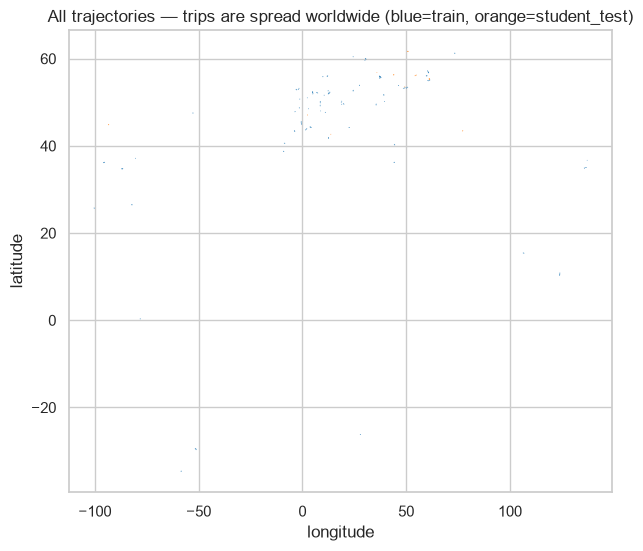

In [6]:
fig, ax = plt.subplots(figsize=(7,6))
for p,c in [('train','tab:blue'),('student_test','tab:orange')]:
    for t in list_trips(p):
        tr=load_trip(p,t)['track']; ax.plot(tr.lon, tr.lat, color=c, lw=0.6, alpha=0.6)
ax.set_xlabel('longitude'); ax.set_ylabel('latitude'); ax.set_title('All trajectories — trips are spread worldwide (blue=train, orange=student_test)')
plt.savefig(f'{FIG}/eda_all_tracks.png', dpi=120); plt.show()

## 5. GPS noise: distance from GPS point to the reference route
How far are raw GPS points from the nearest arc of the ground-truth route? This tells us the candidate search radius.

GPS->route distance (m): median 5.4 | 90% 19.3 | 95% 61.5 | 99% 142.7 | max 570


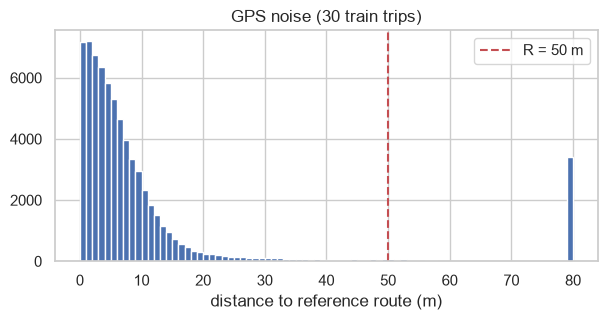

In [7]:
from shapely.geometry import LineString, Point
from shapely import STRtree
from src.data.geo import project, trip_epsg
d_all=[]
for t in list_trips('train')[:30]:
    tr=load_trip('train',t); nodes=tr['nodes']; arcs=tr['arcs']
    ep=trip_epsg(tr['track']); nx_,ny_=project(nodes.lon.values,nodes.lat.values,ep)
    r=tr['route'].arc_id.values
    lines=[LineString([(nx_[u],ny_[u]),(nx_[v],ny_[v])]) for u,v in arcs.loc[r,['u','v']].values]
    tree=STRtree(lines); cl=clean_track(tr['track'],ep)
    pts=[Point(x,y) for x,y in cl[['x','y']].values]
    idx=tree.nearest(pts); d_all.append(np.array([pts[i].distance(lines[j]) for i,j in enumerate(idx)]))
d=np.concatenate(d_all)
print('GPS->route distance (m): median %.1f | 90%% %.1f | 95%% %.1f | 99%% %.1f | max %.0f'%(np.median(d),*np.percentile(d,[90,95,99]),d.max()))
plt.figure(figsize=(7,3)); plt.hist(np.clip(d,0,80),bins=80); plt.axvline(50,color='r',ls='--',label='R = 50 m'); plt.legend()
plt.xlabel('distance to reference route (m)'); plt.title('GPS noise (30 train trips)'); plt.savefig(f'{FIG}/eda_gps_noise.png',dpi=120); plt.show()

## 6. Candidate generation: miss rate per trip

In [8]:
cs=pd.read_csv('../experiments/candidate_stats.csv'); print(cs.groupby('partition').apply(lambda g:(g.miss_rate*g.points).sum()/g.points.sum(), include_groups=False))
cs.sort_values('miss_rate',ascending=False).head(8)

partition
student_test    0.002985
train           0.108688
dtype: float64


,partition,trip,points,rows,pts_no_candidates,miss_rate,median_true_dist_m,seconds
44,train,54,17211,18094,14596,0.883214,138.244075,0.19
26,train,33,5173,29014,44,0.664991,118.432038,0.07
58,train,72,917,6182,0,0.137405,5.596607,0.02
1,train,2,6401,40866,461,0.122950,5.755206,0.10
35,train,43,2278,12473,49,0.079456,10.985476,0.18
49,train,61,1315,9759,0,0.058555,5.362035,0.05
74,train,93,1180,8766,0,0.048305,6.240460,0.08
76,train,96,3158,15075,125,0.039899,4.467910,0.07


## 6b. Effect of cleaning (stationary filter 3 m, gap split 60 s)

In [9]:
rows=[]
for p in ['train','student_test']:
    for t in list_trips(p):
        tr=load_trip(p,t)['track']; cl=clean_track(tr,trip_epsg(tr))
        rows.append(dict(partition=p,trip=t,raw=len(tr),kept=len(cl),segments=cl.seg_id.nunique()))
cln=pd.DataFrame(rows); cln['kept_pct']=100*cln.kept/cln.raw
cln.groupby('partition')[['raw','kept','kept_pct','segments']].mean().round(1)

,raw,kept,kept_pct,segments
partition,,,,
student_test,1916.0,1842.6,96.7,1.1
train,2605.2,2451.2,95.7,1.9


## 7. Folium maps (train trip 00000002 and student_test trip 00000000)

In [10]:
for p,t in [('train','00000002'),('student_test','00000000')]:
    m=trip_map(load_trip(p,t), gps_every=3); m.save(f'../maps/eda_{p}_{t}.html')
print('Saved maps/eda_*.html  (open in a browser; layers: GPS blue, network grey, reference route green)')

Saved maps/eda_*.html  (open in a browser; layers: GPS blue, network grey, reference route green)


## 8. Data-quality notes & assumptions
- No NaNs; timestamps strictly increasing; all route arc ids valid.
- Sampling is ~1 Hz but some trips have long gaps (one train trip > 42 h) → split into segments at > 60 s.
- Each trip ships its **own local road network** (node/arc ids are per-trip, not global).
- Route is an ordered list of arcs, **not** one label per GPS point → we label each point by the nearest route arc (option A).
- The reference route is treated as reference, not perfect truth (GPS noise histogram above).
- Trips are spread worldwide (25 UTM zones, both hemispheres) → each trip is projected into its own UTM zone; distances in metres.
- Train trip 54: most GPS points lie > 50 m from any road (GPS far off the network); train trip 33: reference route offset ~120 m from GPS. Both flagged as label-quality anomalies; their unusable points are excluded from training labels.
- Candidate search R = 50 m, K = 8 → candidate miss rate 0.3% on student_test.